In [6]:
import numpy as np
import openpyxl
import pandas as pd
from google.colab import files
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter
from openpyxl.utils.dataframe import dataframe_to_rows

# Set random seed for reproducible and professional data modeling
np.random.seed(101)

# ==========================================
# 1. GENERATE PARTICIPANT CENSUS DATA
# ==========================================
n_participants = 350
emp_ids = [f"SHUST-EMP-{1000 + i}" for i in range(n_participants)]
divisions = np.random.choice(
    ["Corporate", "Healthcare (403b)", "Public Sector (457b)", "Education"],
    size=n_participants,
    p=[0.4, 0.25, 0.2, 0.15],
)
plan_types = np.where(
    divisions == "Healthcare (403b)",
    "403(b)",
    np.where(
        divisions == "Public Sector (457b)",
        "457(b)",
        np.random.choice(
            ["401(k)", "Defined Benefit (DB)"], size=n_participants, p=[0.7, 0.3]
        ),
    ),
)

ages = np.random.randint(24, 68, size=n_participants)
salaries = np.random.normal(78000, 22000, size=n_participants).clip(
    45000, 165000
).round(2)
deferral_rates = np.where(
    plan_types == "Defined Benefit (DB)",
    0.0,
    np.random.choice(
        [0.0, 0.03, 0.05, 0.06, 0.08, 0.10, 0.12, 0.15],
        size=n_participants,
        p=[0.12, 0.08, 0.22, 0.22, 0.14, 0.12, 0.05, 0.05],
    ),
)

census_df = pd.DataFrame(
    {
        "Employee_ID": emp_ids,
        "Division": divisions,
        "Plan_Type": plan_types,
        "Age": ages,
        "Annual_Salary": salaries,
        "Deferral_Percentage": deferral_rates,
        "Annual_Contribution": (salaries * deferral_rates).round(2),
    }
)

# Export standalone participant census Excel file
census_df.to_excel(
    "Participant_Census.xlsx", sheet_name="Participant Census", index=False
)

# ==========================================
# 2. GENERATE FUND PERFORMANCE & COSTS DATA
# ==========================================
funds = [
    "Vanguard Institutional Index (S&P 500)",
    "BlackRock Russell 2000 Growth",
    "American Funds EuroPacific Growth",
    "Vanguard Total Bond Market Index",
    "PIMCO Income Fund Institutional",
    "Target Retirement 2030",
    "Target Retirement 2040",
    "Target Retirement 2050",
    "Stable Value Fund",
]
asset_classes = [
    "Large Cap Equity",
    "Small Cap Equity",
    "International Equity",
    "Fixed Income",
    "Fixed Income",
    "Target Date",
    "Target Date",
    "Target Date",
    "Stable Value",
]
beg_aum = np.random.uniform(1500000, 8000000, size=len(funds)).round(2)
net_flows = np.random.uniform(-200000, 500000, size=len(funds)).round(2)
ytd_returns = np.random.uniform(-0.03, 0.16, size=len(funds)).round(4)
expense_ratios = np.random.uniform(
    0.0004, 0.0065, size=len(funds)
).round(4)
end_aum = ((beg_aum + net_flows) * (1 + ytd_returns)).round(2)

funds_df = pd.DataFrame(
    {
        "Fund_Name": funds,
        "Asset_Class": asset_classes,
        "Beginning_AUM": beg_aum,
        "Net_Cash_Flow": net_flows,
        "YTD_Return": ytd_returns,
        "Expense_Ratio": expense_ratios,
        "Ending_AUM": end_aum,
    }
)

# Export standalone fund performance Excel file
funds_df.to_excel(
    "Fund_Performance_Costs.xlsx",
    sheet_name="Fund Performance & Costs",
    index=False,
)

# ==========================================
# 3. BUILD EXECUTIVE FINANCIAL MODEL WORKBOOK
# ==========================================
wb = openpyxl.Workbook()

ws_dash = wb.active
ws_dash.title = "Executive Dashboard"
ws_dash.views.sheetView[0].showGridLines = True

ws_census = wb.create_sheet(title="Participant Census")
ws_census.views.sheetView[0].showGridLines = True

ws_inv = wb.create_sheet(title="Fund Performance & Costs")
ws_inv.views.sheetView[0].showGridLines = True

for row in dataframe_to_rows(census_df, index=False, header=True):
    ws_census.append(row)

for row in dataframe_to_rows(funds_df, index=False, header=True):
    ws_inv.append(row)

# Styling Definitions
navy_header_fill = PatternFill(
    start_color="1B365D", end_color="1B365D", fill_type="solid"
)
white_bold_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1B365D")
subtitle_font = Font(name="Calibri", size=11, italic=True, color="555555")
section_font = Font(name="Calibri", size=12, bold=True, color="1B365D")
regular_font = Font(name="Calibri", size=11)
bold_font = Font(name="Calibri", size=11, bold=True)

for ws in [ws_census, ws_inv]:
    for col in range(1, ws.max_column + 1):
        cell = ws.cell(row=1, column=col)
        cell.fill = navy_header_fill
        cell.font = white_bold_font
        cell.alignment = Alignment(horizontal="center", vertical="center")

ws_dash["A1"] = (
    "SHUSTER ADVISORY GROUP | Retirement Plan Analytics & Governance"
)
ws_dash["A1"].font = title_font
ws_dash["A2"] = (
    "Client Plan Sponsor Review: Participation, Performance, and Cost"
    " Efficiency Analysis"
)
ws_dash["A2"].font = subtitle_font

ws_dash["A4"] = "Core Plan Metrics & Fiduciary Benchmarks"
ws_dash["A4"].font = section_font

kpi_headers = ["Metric Description", "Plan Value", "Benchmark Target", "Status"]
for i, h in enumerate(kpi_headers, 1):
    cell = ws_dash.cell(row=5, column=i, value=h)
    cell.fill = navy_header_fill
    cell.font = white_bold_font
    cell.alignment = Alignment(horizontal="center", vertical="center")

kpi_rows = [
    [
        "Overall Plan Participation Rate",
        (
            "=COUNTIF('Participant Census'!F2:F351, \">0\") /"
            " COUNTA('Participant Census'!A2:A351)"
        ),
        0.85,
        "On Track",
    ],
    [
        "Average Employee Deferral Rate",
        "=AVERAGE('Participant Census'!F2:F351)",
        0.075,
        "Review Required",
    ],
    [
        "Total Plan Assets Under Management (AUM)",
        "=SUM('Fund Performance & Costs'!G2:G10)",
        25000000,
        "Optimized",
    ],
    [
        "Weighted Average Fund Expense Ratio",
        (
            "=SUMPRODUCT('Fund Performance & Costs'!G2:G10, 'Fund Performance &"
            " Costs'!F2:F10)/SUM('Fund Performance & Costs'!G2:G10)"
        ),
        0.0035,
        "Cost Efficient",
    ],
    [
        "Multi-Plan Coverage (401k, 403b, 457b, DB)",
        "Active Integration across 4 Plan Types",
        "Multi-Plan Support",
        "Compliant",
    ],
]

for r_idx, r_data in enumerate(kpi_rows, 6):
    ws_dash.cell(row=r_idx, column=1, value=r_data[0]).font = regular_font
    c2 = ws_dash.cell(row=r_idx, column=2, value=r_data[1])
    c2.font = bold_font
    c2.alignment = Alignment(horizontal="right")

    c3 = ws_dash.cell(row=r_idx, column=3, value=r_data[2])
    c3.font = regular_font
    c3.alignment = Alignment(horizontal="right")

    c4 = ws_dash.cell(row=r_idx, column=4, value=r_data[3])
    c4.font = regular_font
    c4.alignment = Alignment(horizontal="center")

ws_dash.cell(row=6, column=2).number_format = "0.0%"
ws_dash.cell(row=6, column=3).number_format = "0.0%"
ws_dash.cell(row=7, column=2).number_format = "0.0%"
ws_dash.cell(row=7, column=3).number_format = "0.0%"
ws_dash.cell(row=8, column=2).number_format = "$#,##0.00"
ws_dash.cell(row=8, column=3).number_format = "$#,##0.00"
ws_dash.cell(row=9, column=2).number_format = "0.00%"
ws_dash.cell(row=9, column=3).number_format = "0.00%"

ws_dash["A13"] = "Participation & Contributions by Retirement Plan Type"
ws_dash["A13"].font = section_font

plan_headers = [
    "Plan Type",
    "Participant Count",
    "Avg. Annual Salary",
    "Avg. Deferral Rate",
    "Total Annual Contributions",
]
for i, h in enumerate(plan_headers, 1):
    cell = ws_dash.cell(row=14, column=i, value=h)
    cell.fill = navy_header_fill
    cell.font = white_bold_font
    cell.alignment = Alignment(horizontal="center", vertical="center")

plan_rows = [
    [
        "401(k)",
        '=COUNTIF(\'Participant Census\'!C2:C351, "401(k)")',
        '=AVERAGEIF(\'Participant Census\'!C2:C351, "401(k)", \'Participant Census\'!E2:E351)',
        '=AVERAGEIF(\'Participant Census\'!C2:C351, "401(k)", \'Participant Census\'!F2:F351)',
        '=SUMIF(\'Participant Census\'!C2:C351, "401(k)", \'Participant Census\'!G2:G351)',
    ],
    [
        "403(b)",
        '=COUNTIF(\'Participant Census\'!C2:C351, "403(b)")',
        '=AVERAGEIF(\'Participant Census\'!C2:C351, "403(b)", \'Participant Census\'!E2:E351)',
        '=AVERAGEIF(\'Participant Census\'!C2:C351, "403(b)", \'Participant Census\'!F2:F351)',
        '=SUMIF(\'Participant Census\'!C2:C351, "403(b)", \'Participant Census\'!G2:G351)',
    ],
    [
        "457(b)",
        '=COUNTIF(\'Participant Census\'!C2:C351, "457(b)")',
        '=AVERAGEIF(\'Participant Census\'!C2:C351, "457(b)", \'Participant Census\'!E2:E351)',
        '=AVERAGEIF(\'Participant Census\'!C2:C351, "457(b)", \'Participant Census\'!F2:F351)',
        '=SUMIF(\'Participant Census\'!C2:C351, "457(b)", \'Participant Census\'!G2:G351)',
    ],
    [
        "Defined Benefit (DB)",
        '=COUNTIF(\'Participant Census\'!C2:C351, "Defined Benefit (DB)")',
        '=AVERAGEIF(\'Participant Census\'!C2:C351, "Defined Benefit (DB)", \'Participant Census\'!E2:E351)',
        '=AVERAGEIF(\'Participant Census\'!C2:C351, "Defined Benefit (DB)", \'Participant Census\'!F2:F351)',
        '=SUMIF(\'Participant Census\'!C2:C351, "Defined Benefit (DB)", \'Participant Census\'!G2:G351)',
    ],
]

for row_idx, r_data in enumerate(plan_rows, 15):
    for col_idx, val in enumerate(r_data, 1):
        cell = ws_dash.cell(row=row_idx, column=col_idx, value=val)
        cell.font = regular_font
        if col_idx == 2:
            cell.number_format = "#,##0"
            cell.alignment = Alignment(horizontal="right")
        elif col_idx == 3:
            cell.number_format = "$#,##0"
            cell.alignment = Alignment(horizontal="right")
        elif col_idx == 4:
            cell.number_format = "0.0%"
            cell.alignment = Alignment(horizontal="right")
        elif col_idx == 5:
            cell.number_format = "$#,##0.00"
            cell.alignment = Alignment(horizontal="right")

for ws in wb.worksheets:
    for col in ws.columns:
        max_len = max(len(str(cell.value or "")) for cell in col)
        col_letter = get_column_letter(col[0].column)
        ws.column_dimensions[col_letter].width = max(max_len + 3, 14)

wb.save("Shuster_Advisory_Group_Retirement_Analytics_Model.xlsx")

# ==========================================
# 4. TRIGGER BROWSER DOWNLOADS
# ==========================================
files.download("Participant_Census.xlsx")
files.download("Fund_Performance_Costs.xlsx")
files.download("Shuster_Advisory_Group_Retirement_Analytics_Model.xlsx")

print("All Excel files successfully generated and downloaded.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All Excel files successfully generated and downloaded.


In [7]:
import numpy as np
import openpyxl
import pandas as pd
from google.colab import files
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter
from openpyxl.utils.dataframe import dataframe_to_rows

# Set random seed for reproducible and professional data modeling
np.random.seed(101)

# ==========================================
# 1. GENERATE PARTICIPANT CENSUS DATA
# ==========================================
n_participants = 350
emp_ids = [f"SHUST-EMP-{1000 + i}" for i in range(n_participants)]
divisions = np.random.choice(
    ["Corporate", "Healthcare (403b)", "Public Sector (457b)", "Education"],
    size=n_participants,
    p=[0.4, 0.25, 0.2, 0.15],
)
plan_types = np.where(
    divisions == "Healthcare (403b)",
    "403(b)",
    np.where(
        divisions == "Public Sector (457b)",
        "457(b)",
        np.random.choice(
            ["401(k)", "Defined Benefit (DB)"], size=n_participants, p=[0.7, 0.3]
        ),
    ),
)

ages = np.random.randint(24, 68, size=n_participants)
salaries = np.random.normal(78000, 22000, size=n_participants).clip(
    45000, 165000
).round(2)
deferral_rates = np.where(
    plan_types == "Defined Benefit (DB)",
    0.0,
    np.random.choice(
        [0.0, 0.03, 0.05, 0.06, 0.08, 0.10, 0.12, 0.15],
        size=n_participants,
        p=[0.12, 0.08, 0.22, 0.22, 0.14, 0.12, 0.05, 0.05],
    ),
)

census_df = pd.DataFrame(
    {
        "Employee_ID": emp_ids,
        "Division": divisions,
        "Plan_Type": plan_types,
        "Age": ages,
        "Annual_Salary": salaries,
        "Deferral_Percentage": deferral_rates,
        "Annual_Contribution": (salaries * deferral_rates).round(2),
    }
)

# Export standalone participant census Excel file
census_df.to_excel(
    "Participant_Census.xlsx", sheet_name="Participant Census", index=False
)

# ==========================================
# 2. GENERATE FUND PERFORMANCE & COSTS DATA
# ==========================================
funds = [
    "Vanguard Institutional Index (S&P 500)",
    "BlackRock Russell 2000 Growth",
    "American Funds EuroPacific Growth",
    "Vanguard Total Bond Market Index",
    "PIMCO Income Fund Institutional",
    "Target Retirement 2030",
    "Target Retirement 2040",
    "Target Retirement 2050",
    "Stable Value Fund",
]
asset_classes = [
    "Large Cap Equity",
    "Small Cap Equity",
    "International Equity",
    "Fixed Income",
    "Fixed Income",
    "Target Date",
    "Target Date",
    "Target Date",
    "Stable Value",
]
beg_aum = np.random.uniform(1500000, 8000000, size=len(funds)).round(2)
net_flows = np.random.uniform(-200000, 500000, size=len(funds)).round(2)
ytd_returns = np.random.uniform(-0.03, 0.16, size=len(funds)).round(4)
expense_ratios = np.random.uniform(
    0.0004, 0.0065, size=len(funds)
).round(4)
end_aum = ((beg_aum + net_flows) * (1 + ytd_returns)).round(2)

funds_df = pd.DataFrame(
    {
        "Fund_Name": funds,
        "Asset_Class": asset_classes,
        "Beginning_AUM": beg_aum,
        "Net_Cash_Flow": net_flows,
        "YTD_Return": ytd_returns,
        "Expense_Ratio": expense_ratios,
        "Ending_AUM": end_aum,
    }
)

# Export standalone fund performance Excel file
funds_df.to_excel(
    "Fund_Performance_Costs.xlsx",
    sheet_name="Fund Performance & Costs",
    index=False,
)

# ==========================================
# 3. BUILD EXECUTIVE FINANCIAL MODEL WORKBOOK
# ==========================================
wb = openpyxl.Workbook()

ws_dash = wb.active
ws_dash.title = "Executive Dashboard"
ws_dash.views.sheetView[0].showGridLines = True

ws_census = wb.create_sheet(title="Participant Census")
ws_census.views.sheetView[0].showGridLines = True

ws_inv = wb.create_sheet(title="Fund Performance & Costs")
ws_inv.views.sheetView[0].showGridLines = True

for row in dataframe_to_rows(census_df, index=False, header=True):
    ws_census.append(row)

for row in dataframe_to_rows(funds_df, index=False, header=True):
    ws_inv.append(row)

# Styling Definitions
navy_header_fill = PatternFill(
    start_color="1B365D", end_color="1B365D", fill_type="solid"
)
white_bold_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1B365D")
subtitle_font = Font(name="Calibri", size=11, italic=True, color="555555")
section_font = Font(name="Calibri", size=12, bold=True, color="1B365D")
regular_font = Font(name="Calibri", size=11)
bold_font = Font(name="Calibri", size=11, bold=True)

for ws in [ws_census, ws_inv]:
    for col in range(1, ws.max_column + 1):
        cell = ws.cell(row=1, column=col)
        cell.fill = navy_header_fill
        cell.font = white_bold_font
        cell.alignment = Alignment(horizontal="center", vertical="center")

ws_dash["A1"] = (
    "SHUSTER ADVISORY GROUP | Retirement Plan Analytics & Governance"
)
ws_dash["A1"].font = title_font
ws_dash["A2"] = (
    "Client Plan Sponsor Review: Participation, Performance, and Cost"
    " Efficiency Analysis"
)
ws_dash["A2"].font = subtitle_font

ws_dash["A4"] = "Core Plan Metrics & Fiduciary Benchmarks"
ws_dash["A4"].font = section_font

kpi_headers = ["Metric Description", "Plan Value", "Benchmark Target", "Status"]
for i, h in enumerate(kpi_headers, 1):
    cell = ws_dash.cell(row=5, column=i, value=h)
    cell.fill = navy_header_fill
    cell.font = white_bold_font
    cell.alignment = Alignment(horizontal="center", vertical="center")

kpi_rows = [
    [
        "Overall Plan Participation Rate",
        (
            "=COUNTIF('Participant Census'!F2:F351, \">0\") /"
            " COUNTA('Participant Census'!A2:A351)"
        ),
        0.85,
        "On Track",
    ],
    [
        "Average Employee Deferral Rate",
        "=AVERAGE('Participant Census'!F2:F351)",
        0.075,
        "Review Required",
    ],
    [
        "Total Plan Assets Under Management (AUM)",
        "=SUM('Fund Performance & Costs'!G2:G10)",
        25000000,
        "Optimized",
    ],
    [
        "Weighted Average Fund Expense Ratio",
        (
            "=SUMPRODUCT('Fund Performance & Costs'!G2:G10, 'Fund Performance &"
            " Costs'!F2:F10)/SUM('Fund Performance & Costs'!G2:G10)"
        ),
        0.0035,
        "Cost Efficient",
    ],
    [
        "Multi-Plan Coverage (401k, 403b, 457b, DB)",
        "Active Integration across 4 Plan Types",
        "Multi-Plan Support",
        "Compliant",
    ],
]

for r_idx, r_data in enumerate(kpi_rows, 6):
    ws_dash.cell(row=r_idx, column=1, value=r_data[0]).font = regular_font
    c2 = ws_dash.cell(row=r_idx, column=2, value=r_data[1])
    c2.font = bold_font
    c2.alignment = Alignment(horizontal="right")

    c3 = ws_dash.cell(row=r_idx, column=3, value=r_data[2])
    c3.font = regular_font
    c3.alignment = Alignment(horizontal="right")

    c4 = ws_dash.cell(row=r_idx, column=4, value=r_data[3])
    c4.font = regular_font
    c4.alignment = Alignment(horizontal="center")

ws_dash.cell(row=6, column=2).number_format = "0.0%"
ws_dash.cell(row=6, column=3).number_format = "0.0%"
ws_dash.cell(row=7, column=2).number_format = "0.0%"
ws_dash.cell(row=7, column=3).number_format = "0.0%"
ws_dash.cell(row=8, column=2).number_format = "$#,##0.00"
ws_dash.cell(row=8, column=3).number_format = "$#,##0.00"
ws_dash.cell(row=9, column=2).number_format = "0.00%"
ws_dash.cell(row=9, column=3).number_format = "0.00%"

ws_dash["A13"] = "Participation & Contributions by Retirement Plan Type"
ws_dash["A13"].font = section_font

plan_headers = [
    "Plan Type",
    "Participant Count",
    "Avg. Annual Salary",
    "Avg. Deferral Rate",
    "Total Annual Contributions",
]
for i, h in enumerate(plan_headers, 1):
    cell = ws_dash.cell(row=14, column=i, value=h)
    cell.fill = navy_header_fill
    cell.font = white_bold_font
    cell.alignment = Alignment(horizontal="center", vertical="center")

plan_rows = [
    [
        "401(k)",
        '=COUNTIF(\'Participant Census\'!C2:C351, "401(k)")',
        (
            '=AVERAGEIF(\'Participant Census\'!C2:C351, "401(k)", \'Participant'
            " Census\'!E2:E351)"
        ),
        (
            '=AVERAGEIF(\'Participant Census\'!C2:C351, "401(k)", \'Participant'
            " Census\'!F2:F351)"
        ),
        (
            '=SUMIF(\'Participant Census\'!C2:C351, "401(k)", \'Participant'
            " Census\'!G2:G351)"
        ),
    ],
    [
        "403(b)",
        '=COUNTIF(\'Participant Census\'!C2:C351, "403(b)")',
        (
            '=AVERAGEIF(\'Participant Census\'!C2:C351, "403(b)", \'Participant'
            " Census\'!E2:E351)"
        ),
        (
            '=AVERAGEIF(\'Participant Census\'!C2:C351, "403(b)", \'Participant'
            " Census\'!F2:F351)"
        ),
        (
            '=SUMIF(\'Participant Census\'!C2:C351, "403(b)", \'Participant'
            " Census\'!G2:G351)"
        ),
    ],
    [
        "457(b)",
        '=COUNTIF(\'Participant Census\'!C2:C351, "457(b)")',
        (
            '=AVERAGEIF(\'Participant Census\'!C2:C351, "457(b)", \'Participant'
            " Census\'!E2:E351)"
        ),
        (
            '=AVERAGEIF(\'Participant Census\'!C2:C351, "457(b)", \'Participant'
            " Census\'!F2:F351)"
        ),
        (
            '=SUMIF(\'Participant Census\'!C2:C351, "457(b)", \'Participant'
            " Census\'!G2:G351)"
        ),
    ],
    [
        "Defined Benefit (DB)",
        '=COUNTIF(\'Participant Census\'!C2:C351, "Defined Benefit (DB)")',
        (
            '=AVERAGEIF(\'Participant Census\'!C2:C351, "Defined Benefit'
            " (DB)\", 'Participant Census'!E2:E351)"
        ),
        (
            '=AVERAGEIF(\'Participant Census\'!C2:C351, "Defined Benefit'
            " (DB)\", 'Participant Census'!F2:F351)"
        ),
        (
            '=SUMIF(\'Participant Census\'!C2:C351, "Defined Benefit'
            " (DB)\", 'Participant Census'!G2:G351)"
        ),
    ],
]

for row_idx, r_data in enumerate(plan_rows, 15):
    for col_idx, val in enumerate(r_data, 1):
        cell = ws_dash.cell(row=row_idx, column=col_idx, value=val)
        cell.font = regular_font
        if col_idx == 2:
            cell.number_format = "#,##0"
            cell.alignment = Alignment(horizontal="right")
        elif col_idx == 3:
            cell.number_format = "$#,##0"
            cell.alignment = Alignment(horizontal="right")
        elif col_idx == 4:
            cell.number_format = "0.0%"
            cell.alignment = Alignment(horizontal="right")
        elif col_idx == 5:
            cell.number_format = "$#,##0.00"
            cell.alignment = Alignment(horizontal="right")

for ws in wb.worksheets:
    for col in ws.columns:
        max_len = max(len(str(cell.value or "")) for cell in col)
        col_letter = get_column_letter(col[0].column)
        ws.column_dimensions[col_letter].width = max(max_len + 3, 14)

wb.save("Shuster_Advisory_Group_Retirement_Analytics_Model.xlsx")

# ==========================================
# 4. TRIGGER BROWSER DOWNLOADS
# ==========================================
files.download("Participant_Census.xlsx")
files.download("Fund_Performance_Costs.xlsx")
files.download("Shuster_Advisory_Group_Retirement_Analytics_Model.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

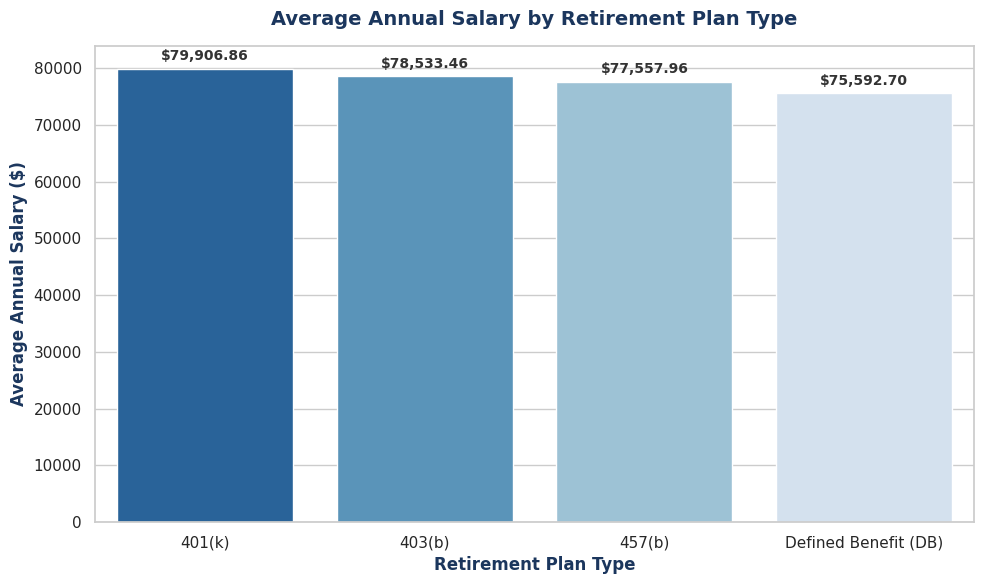

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group the census data by Plan Type and calculate the average salary
salary_by_plan = census_df.groupby('Plan_Type')['Annual_Salary'].mean().reset_index()

# Set the aesthetic style for the plot
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Create the bar chart
ax = sns.barplot(
    x='Plan_Type',
    y='Annual_Salary',
    data=salary_by_plan,
    palette='Blues_r',
    hue='Plan_Type',
    legend=False
)

# Format the chart labels and title with Shuster theme styling
plt.title('Average Annual Salary by Retirement Plan Type', fontsize=14, fontweight='bold', pad=15, color='#1B365D')
plt.xlabel('Retirement Plan Type', fontsize=12, fontweight='bold', color='#1B365D')
plt.ylabel('Average Annual Salary ($)', fontsize=12, fontweight='bold', color='#1B365D')

# Add values on top of each bar
for p in ax.patches:
    ax.annotate(
        f"${p.get_height():,.2f}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center',
        xytext=(0, 9),
        textcoords='offset points',
        fontsize=10, fontweight='bold', color='#333333'
    )

# Improve layout
plt.tight_layout()
plt.show()

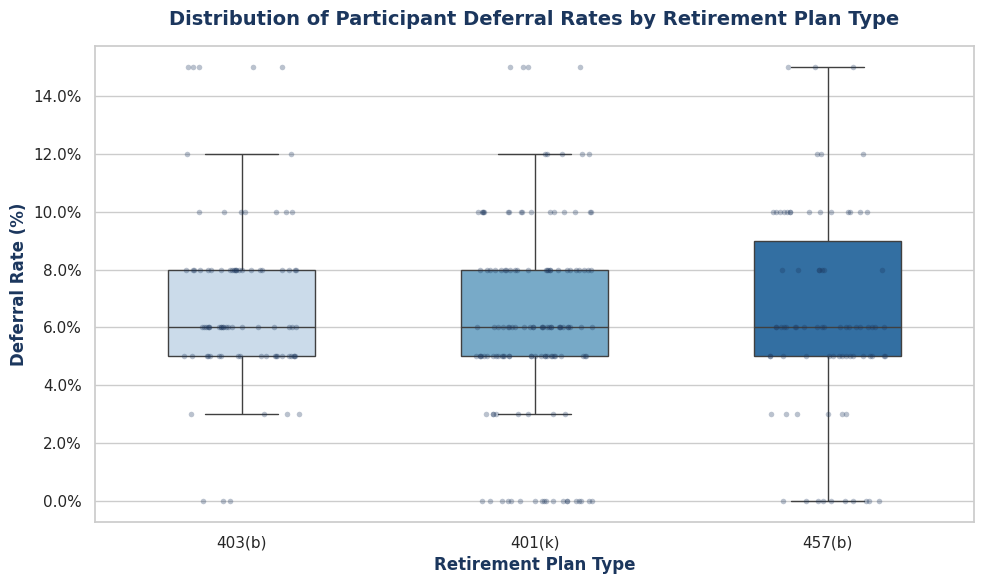

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter out 'Defined Benefit (DB)' plan type as its deferral rate is always 0%
census_filtered = census_df[census_df['Plan_Type'] != 'Defined Benefit (DB)']

# Set professional theme matching the Shuster corporate styling
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Create a boxplot overlaid with a stripplot to show both summary stats and individual distribution
ax = sns.boxplot(
    x='Plan_Type',
    y='Deferral_Percentage',
    data=census_filtered,
    palette='Blues',
    hue='Plan_Type',
    legend=False,
    width=0.5,
    showfliers=False
)
sns.stripplot(
    x='Plan_Type',
    y='Deferral_Percentage',
    data=census_filtered,
    color='#1B365D',
    alpha=0.3,
    size=4,
    jitter=0.2
)

# Format the Y-axis as percentage
import matplotlib.ticker as mtick
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# Title and Label Customizations with Shuster palette
plt.title('Distribution of Participant Deferral Rates by Retirement Plan Type', fontsize=14, fontweight='bold', pad=15, color='#1B365D')
plt.xlabel('Retirement Plan Type', fontsize=12, fontweight='bold', color='#1B365D')
plt.ylabel('Deferral Rate (%)', fontsize=12, fontweight='bold', color='#1B365D')

plt.tight_layout()
plt.show()

In [10]:
import pandas as pd

# Calculate key aggregate metrics for Shuster Advisory Group
total_beg_aum = funds_df['Beginning_AUM'].sum()
total_net_flow = funds_df['Net_Cash_Flow'].sum()
total_end_aum = funds_df['Ending_AUM'].sum()

simple_avg_return = funds_df['YTD_Return'].mean()
weighted_avg_return = (funds_df['YTD_Return'] * funds_df['Ending_AUM']).sum() / total_end_aum

simple_avg_expense = funds_df['Expense_Ratio'].mean()
weighted_avg_expense = (funds_df['Expense_Ratio'] * funds_df['Ending_AUM']).sum() / total_end_aum

# Create a professional summary DataFrame
summary_data = {
    'Fiduciary Metric': [
        'Total Beginning AUM ($)',
        'Total Net Cash Flow ($)',
        'Total Ending AUM ($)',
        'Simple Average YTD Return (%)',
        'Weighted Average YTD Return (%)',
        'Simple Average Expense Ratio (%)',
        'Weighted Average Expense Ratio (%)'
    ],
    'Value': [
        total_beg_aum,
        total_net_flow,
        total_end_aum,
        simple_avg_return,
        weighted_avg_return,
        simple_avg_expense,
        weighted_avg_expense
    ]
}

summary_df = pd.DataFrame(summary_data)

# Formatting values for executive output
def format_metric(row):
    metric = row['Fiduciary Metric']
    val = row['Value']
    if '$' in metric:
        return f"${val:,.2f}"
    else:
        return f"{val * 100:.3f}%"

summary_df['Value_Formatted'] = summary_df.apply(format_metric, axis=1)
summary_display = summary_df[['Fiduciary Metric', 'Value_Formatted']]

print("SHUSTER ADVISORY GROUP | FUND PERFORMANCE & COSTS EXECUTIVE SUMMARY\n" + "="*70)
display(summary_display)


SHUSTER ADVISORY GROUP | FUND PERFORMANCE & COSTS EXECUTIVE SUMMARY


,Fiduciary Metric,Value_Formatted
0,Total Beginning AUM ($),"$33,371,997.24"
1,Total Net Cash Flow ($),"$210,602.53"
2,Total Ending AUM ($),"$35,496,745.48"
3,Simple Average YTD Return (%),6.020%
4,Weighted Average YTD Return (%),5.928%
5,Simple Average Expense Ratio (%),0.436%
6,Weighted Average Expense Ratio (%),0.410%


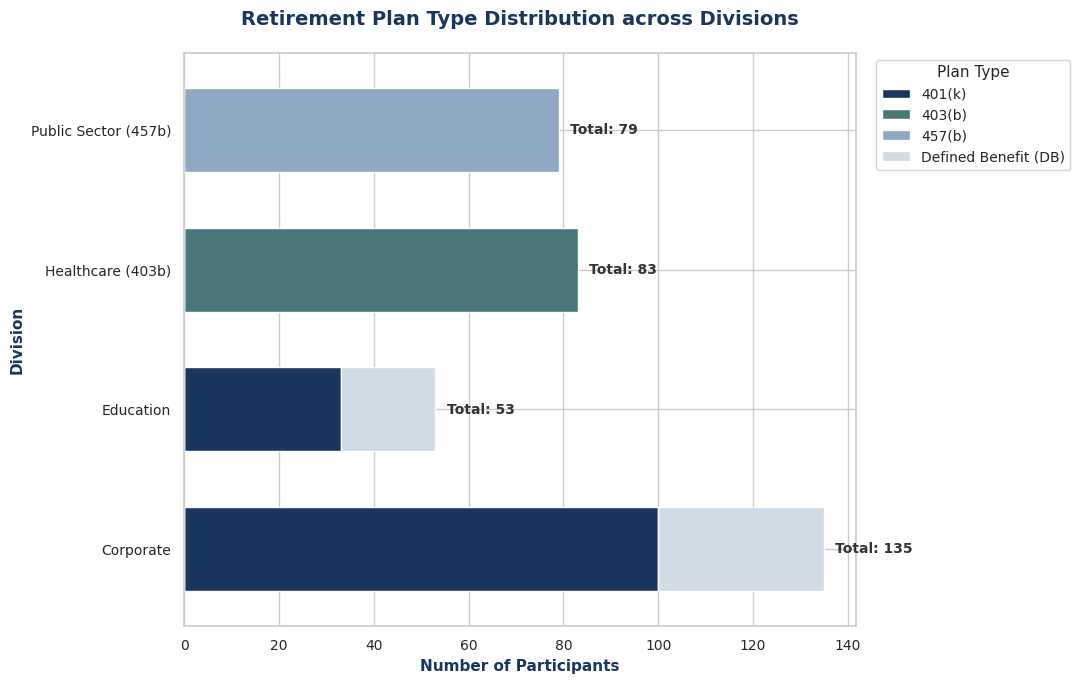

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group and cross-tabulate Division and Plan Type
div_plan_ct = pd.crosstab(census_df['Division'], census_df['Plan_Type'])

# Configure styling with matching corporate brand palette (Blues/Navy theme)
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 7))

# Plot stacked bar chart
custom_colors = ['#1B365D', '#4A777A', '#8FA9C4', '#D0DBE5']
div_plan_ct.plot(
    kind='barh',
    stacked=True,
    color=custom_colors[:len(div_plan_ct.columns)],
    ax=ax,
    edgecolor='white',
    width=0.6
)

# Formatting labels, title, and legend
plt.title('Retirement Plan Type Distribution across Divisions', fontsize=14, fontweight='bold', pad=20, color='#1B365D')
plt.xlabel('Number of Participants', fontsize=11, fontweight='bold', color='#1B365D')
plt.ylabel('Division', fontsize=11, fontweight='bold', color='#1B365D')
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Place legend beautifully on the upper right side
plt.legend(title='Plan Type', title_fontsize=11, fontsize=10, bbox_to_anchor=(1.02, 1), loc='upper left')

# Add total counts annotation at the end of each stacked bar
for idx, row in enumerate(div_plan_ct.sum(axis=1)):
    ax.annotate(
        f"Total: {row}",
        (row, idx),
        xytext=(8, -3),
        textcoords='offset points',
        fontsize=10,
        fontweight='bold',
        color='#333333'
    )

plt.tight_layout()
plt.show()